# Step2 3주차 모델 비교와 통계 검정

오성빈 · 2026-10-20

이 노트북은 `python week3.py`로 생성한 실제 실험 결과를 읽어 재현 가능한 표와 그림으로 확인한다.
모델을 처음부터 학습하려면 `python -m pip install -r requirements-week3.txt` 후 `python week3.py --output outputs/week3_new`를 실행하고 아래 OUT을 변경한다.
기본 결과는 SVM·RF·XGBoost, 고정 파라미터, 동일 시행 분할, 학습 부분만의 5-fold 교차검증으로 생성했다.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
OUT=Path('outputs/week3')
r=json.loads((OUT/'results.json').read_text(encoding='utf-8'))
config=json.loads((OUT/'config.json').read_text())
display(config)

{'dataset_sha256': 'b4217af8541d3fd87937dde9d50cba84c214d91eec9e744c1e3431f3c9f8dd4e',
 'seed': 42,
 'jobs': 4,
 'versions': {'numpy': '2.5.3',
  'pandas': '3.0.5',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'xgboost': '3.4.1',
  'matplotlib': '3.11.2'},
 'python': '3.12.14',
 'platform': 'Windows-11-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel',
 'logical_cpus': 20,
 'parameters': {'SVM': {'C': 1.0,
   'break_ties': False,
   'cache_size': 1024,
   'class_weight': None,
   'coef0': 0.0,
   'decision_function_shape': 'ovr',
   'degree': 3,
   'gamma': 'scale',
   'kernel': 'rbf',
   'max_iter': -1,
   'probability': 'deprecated',
   'random_state': 42,
   'shrinking': True,
   'tol': 0.001,
   'verbose': False},
  'RF': {'bootstrap': True,
   'ccp_alpha': 0.0,
   'class_weight': None,
   'criterion': 'gini',
   'max_depth': None,
   'max_features': 'sqrt',
   'max_leaf_nodes': None,
   'max_samples': None,
   'min_impurity_decrease': 0.0,
 

## 홀드아웃 평가
Precision·Recall·F1은 macro 평균이다. 윈도우 단위 지표이며 테스트 창은 클래스당 912개다.

In [2]:
display(pd.read_csv(OUT/'holdout_metrics.csv'))

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,single_sample_mean_ms,single_sample_median_ms,single_sample_p95_ms,batch_seconds,batch_ms_per_window
0,SVM,0.496162,0.500736,0.496162,0.496447,19.173016,1.563572,1.52430,1.796710,9.990177,1.369268
1,RF,0.658717,0.660936,0.658717,0.659033,2.030945,12.527413,12.52635,12.886265,0.037535,0.005145
2,XGB,0.641036,0.644400,0.641036,0.641512,5.369771,0.734423,0.70180,1.006115,0.060609,0.008307


## 학습 데이터 내부 시행 단위 교차검증
같은 시행의 19개 창은 동일 fold에 배정한다. StandardScaler는 각 fold의 학습 부분에서만 fit한다. SD는 ddof=0이며 신뢰구간이 아니다.

,model,fold,train_trials,validation_trials,train_windows,validation_windows,fit_seconds,accuracy,precision_macro,recall_macro,f1_macro
0,SVM,1,1228,308,23332,5852,14.269783,0.462577,0.468152,0.462702,0.463637
1,RF,1,1228,308,23332,5852,2.211036,0.615858,0.615332,0.615829,0.615033
2,XGB,1,1228,308,23332,5852,7.064951,0.608339,0.609161,0.608415,0.608271
3,SVM,2,1229,307,23351,5833,15.490326,0.462198,0.469485,0.462200,0.462714
4,RF,2,1229,307,23351,5833,2.049388,0.632608,0.632733,0.632378,0.632184
5,XGB,2,1229,307,23351,5833,5.434892,0.620778,0.621722,0.620650,0.620691
6,SVM,3,1229,307,23351,5833,13.240763,0.458941,0.465680,0.459177,0.459562
7,RF,3,1229,307,23351,5833,2.033128,0.634836,0.636802,0.634913,0.635027
8,XGB,3,1229,307,23351,5833,5.177642,0.621121,0.625687,0.621315,0.622297
9,SVM,4,1229,307,23351,5833,14.549913,0.494600,0.501088,0.494748,0.495470


,model,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std
0,SVM,0.468583,0.013134,0.469279,0.013218
1,RF,0.634024,0.010418,0.633815,0.010747
2,XGB,0.619696,0.006947,0.619766,0.006850


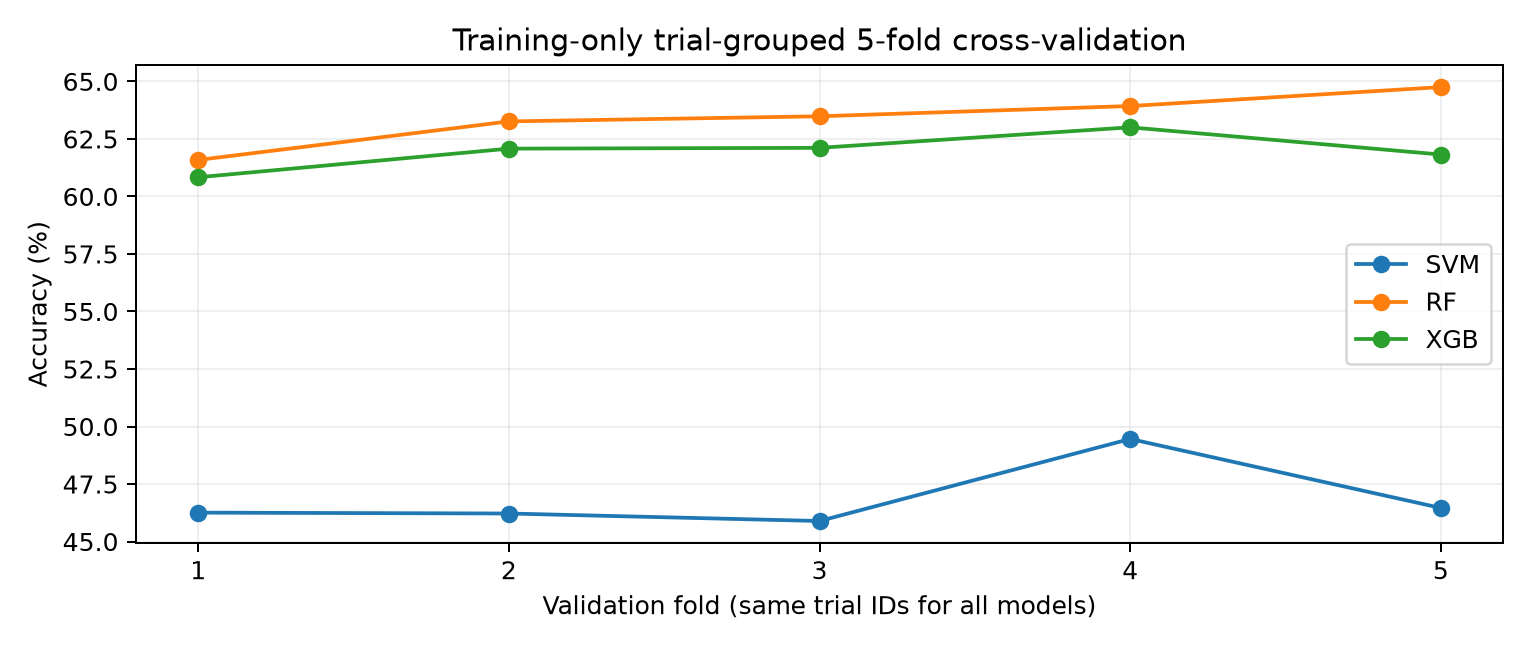

In [3]:
display(pd.read_csv(OUT/'cv_scores.csv'))
display(pd.read_csv(OUT/'cv_summary.csv'))
display(Image(filename=str(OUT/'cv_accuracy.png')))

## 대응표본 t 검정
같은 5개 fold의 정확도를 짝지었다. 원 p값과 세 쌍 비교의 Holm 보정 p값을 함께 제시한다. fold 간 학습 데이터가 겹치므로 독립성이 보장되지 않으며 탐색적으로 해석한다. p≥0.05는 동등성의 증거가 아니다.

In [4]:
display(pd.read_csv(OUT/'paired_tests.csv'))

,model_a,model_b,n_pairs,mean_accuracy_difference,t,p_raw,p_holm
0,SVM,RF,5,-0.165441,-23.189378,0.000020,0.000041
1,SVM,XGB,5,-0.151114,-31.547928,0.000006,0.000018
2,RF,XGB,5,0.014327,3.678932,0.021224,0.021224


## 혼동행렬과 오류 구조
행은 실제 클래스, 열은 예측 클래스다. 동작과 각도 의미를 분리하여 오류를 집계했다.

SVM


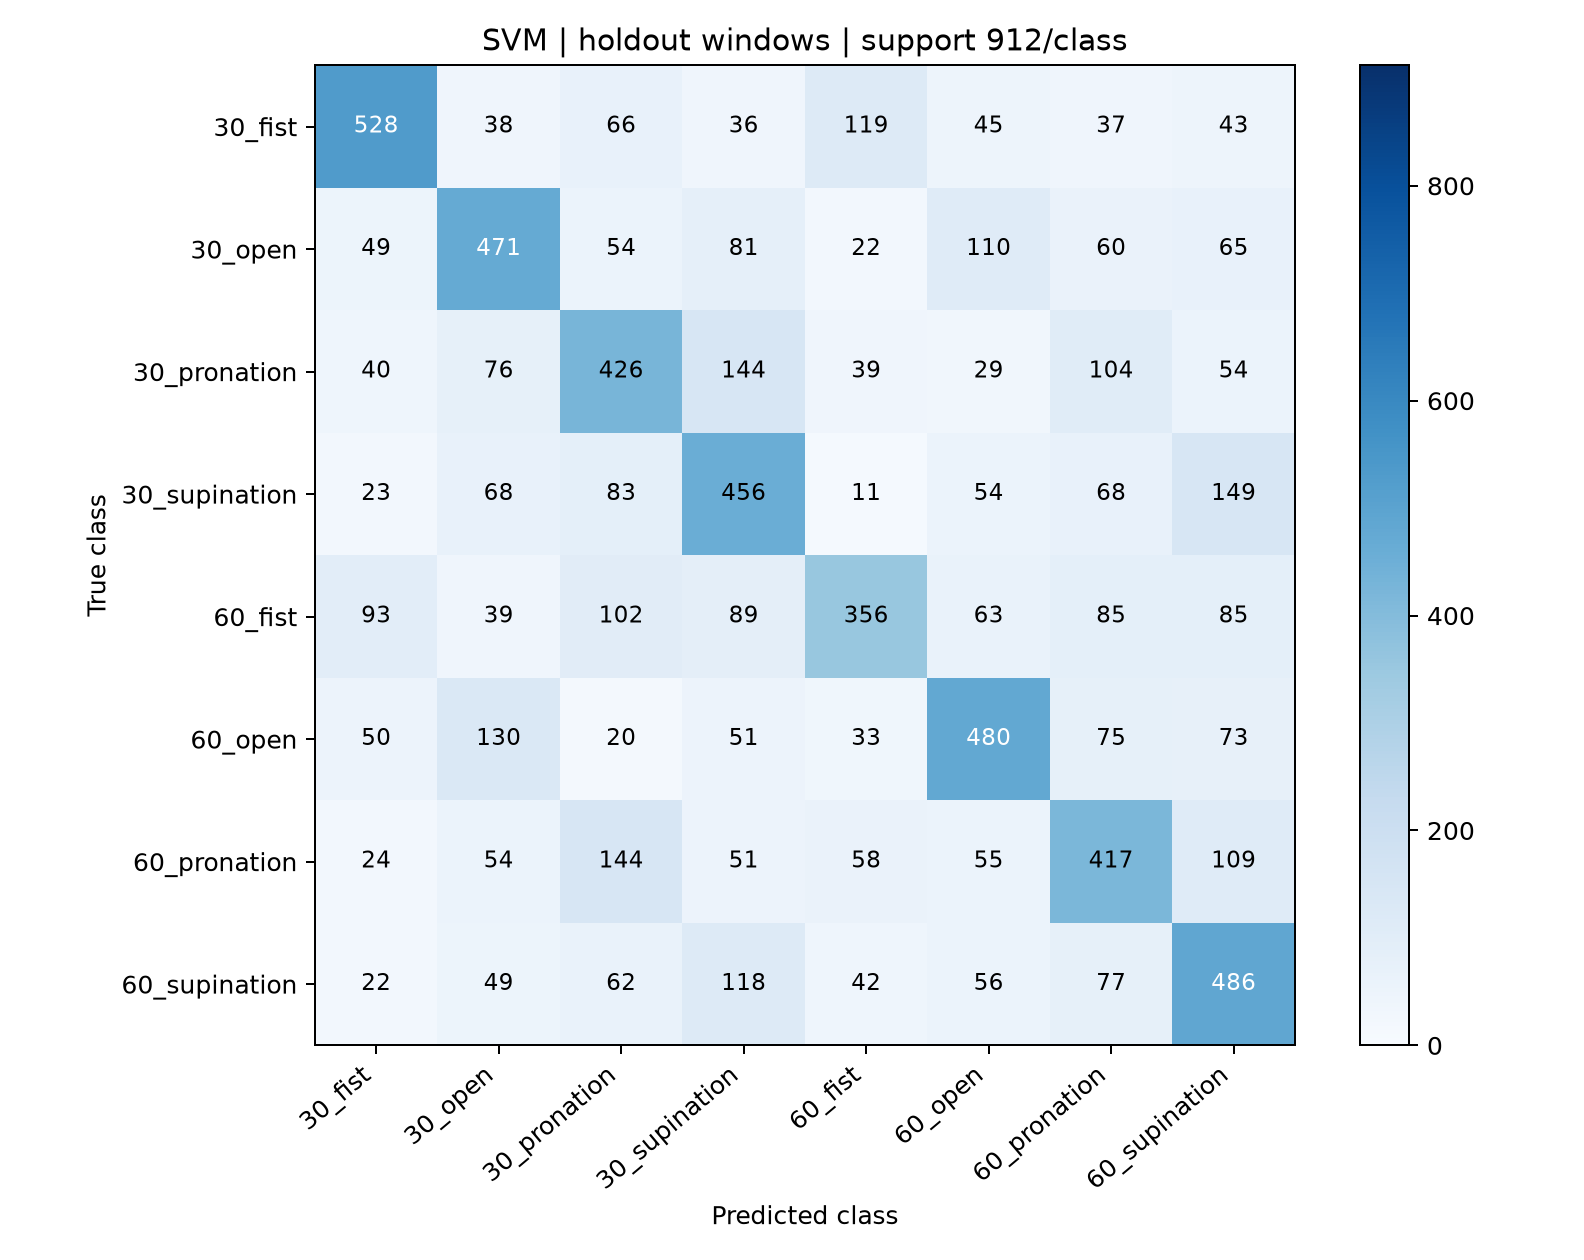

{'confusion': [[528, 38, 66, 36, 119, 45, 37, 43],
  [49, 471, 54, 81, 22, 110, 60, 65],
  [40, 76, 426, 144, 39, 29, 104, 54],
  [23, 68, 83, 456, 11, 54, 68, 149],
  [93, 39, 102, 89, 356, 63, 85, 85],
  [50, 130, 20, 51, 33, 480, 75, 73],
  [24, 54, 144, 51, 58, 55, 417, 109],
  [22, 49, 62, 118, 42, 56, 77, 486]],
 'class_recall': [0.5789473684210527,
  0.5164473684210527,
  0.46710526315789475,
  0.5,
  0.39035087719298245,
  0.5263157894736842,
  0.45723684210526316,
  0.5328947368421053],
 'error_types': {'same_gesture_wrong_angle': 967,
  'same_angle_wrong_gesture': 1569,
  'both_wrong': 1140},
 'errors': 3676,
 'top_errors': [{'actual': '30_supination',
   'predicted': '60_supination',
   'count': 149},
  {'actual': '30_pronation', 'predicted': '30_supination', 'count': 144},
  {'actual': '60_pronation', 'predicted': '30_pronation', 'count': 144},
  {'actual': '60_open', 'predicted': '30_open', 'count': 130},
  {'actual': '30_fist', 'predicted': '60_fist', 'count': 119}],
 'be

RF


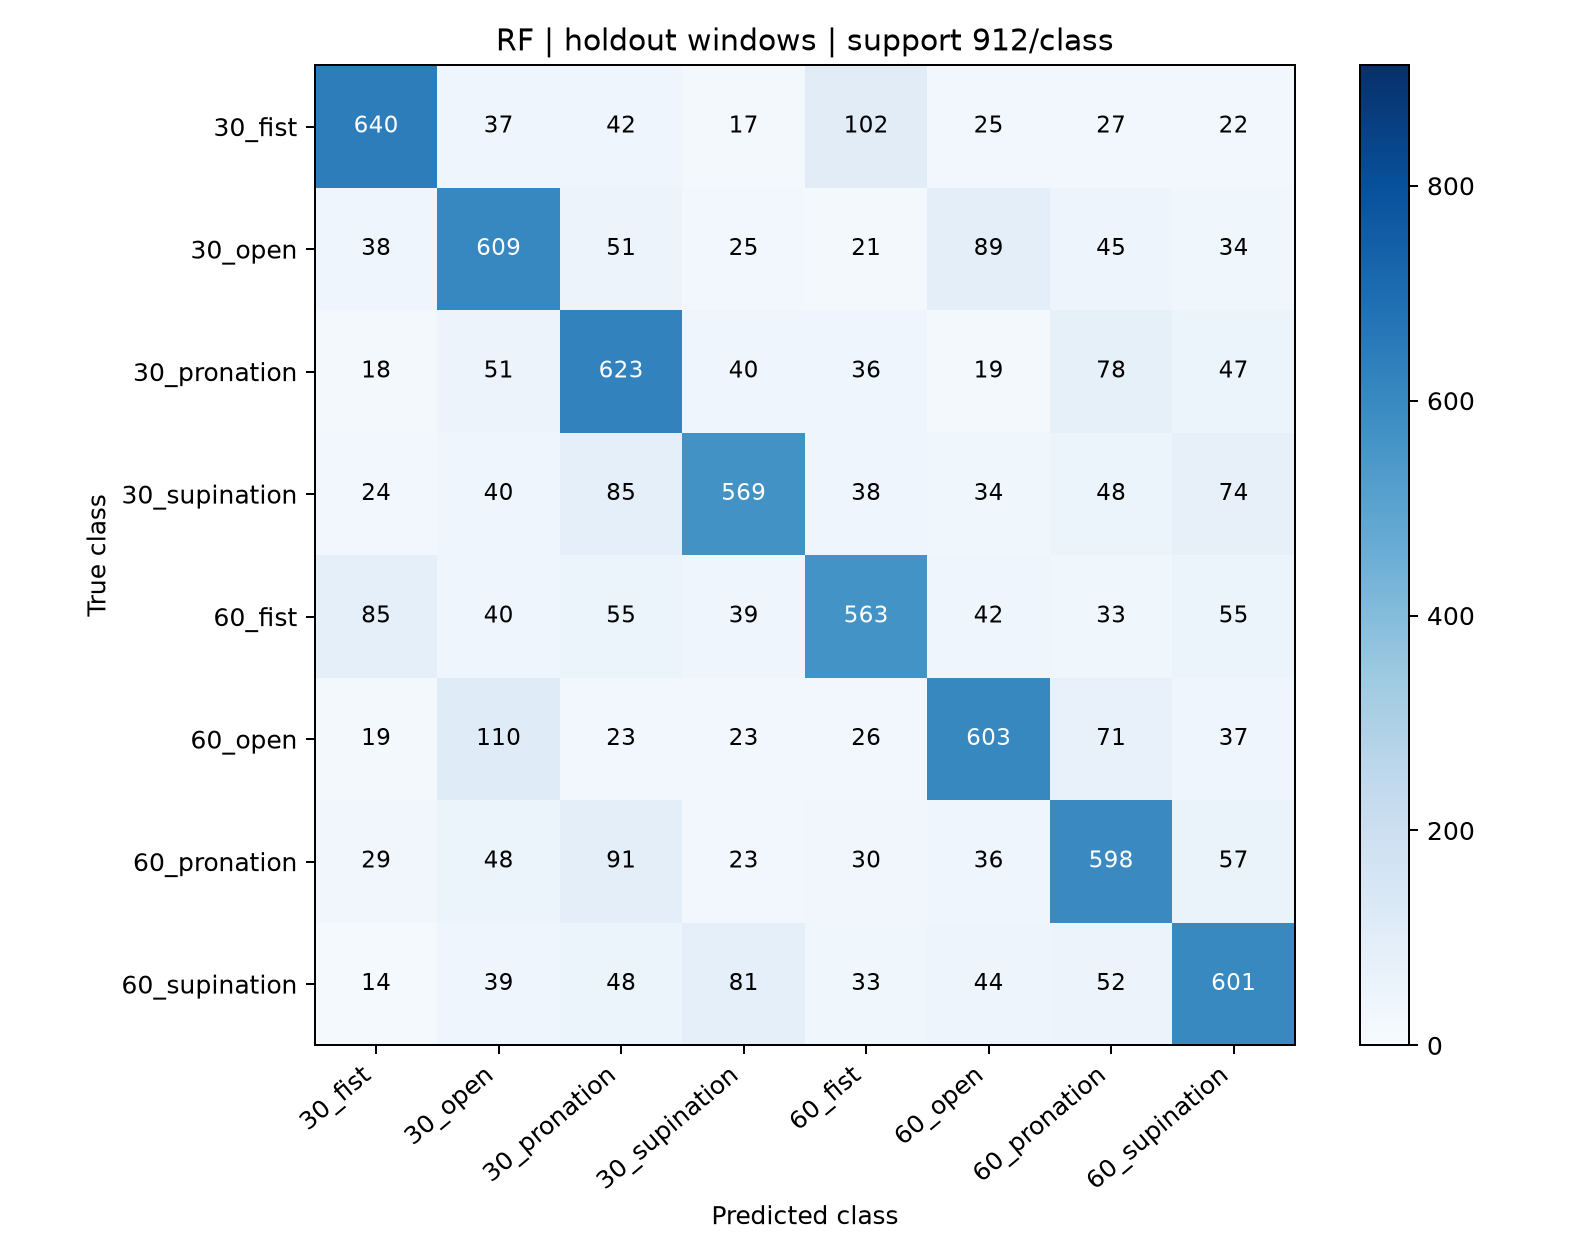

{'confusion': [[640, 37, 42, 17, 102, 25, 27, 22],
  [38, 609, 51, 25, 21, 89, 45, 34],
  [18, 51, 623, 40, 36, 19, 78, 47],
  [24, 40, 85, 569, 38, 34, 48, 74],
  [85, 40, 55, 39, 563, 42, 33, 55],
  [19, 110, 23, 23, 26, 603, 71, 37],
  [29, 48, 91, 23, 30, 36, 598, 57],
  [14, 39, 48, 81, 33, 44, 52, 601]],
 'class_recall': [0.7017543859649122,
  0.6677631578947368,
  0.6831140350877193,
  0.6239035087719298,
  0.6173245614035088,
  0.6611842105263158,
  0.6557017543859649,
  0.6589912280701754],
 'error_types': {'same_gesture_wrong_angle': 710,
  'same_angle_wrong_gesture': 984,
  'both_wrong': 796},
 'errors': 2490,
 'top_errors': [{'actual': '60_open', 'predicted': '30_open', 'count': 110},
  {'actual': '30_fist', 'predicted': '60_fist', 'count': 102},
  {'actual': '60_pronation', 'predicted': '30_pronation', 'count': 91},
  {'actual': '30_open', 'predicted': '60_open', 'count': 89},
  {'actual': '30_supination', 'predicted': '30_pronation', 'count': 85}],
 'best_classes': ['30_f

XGB


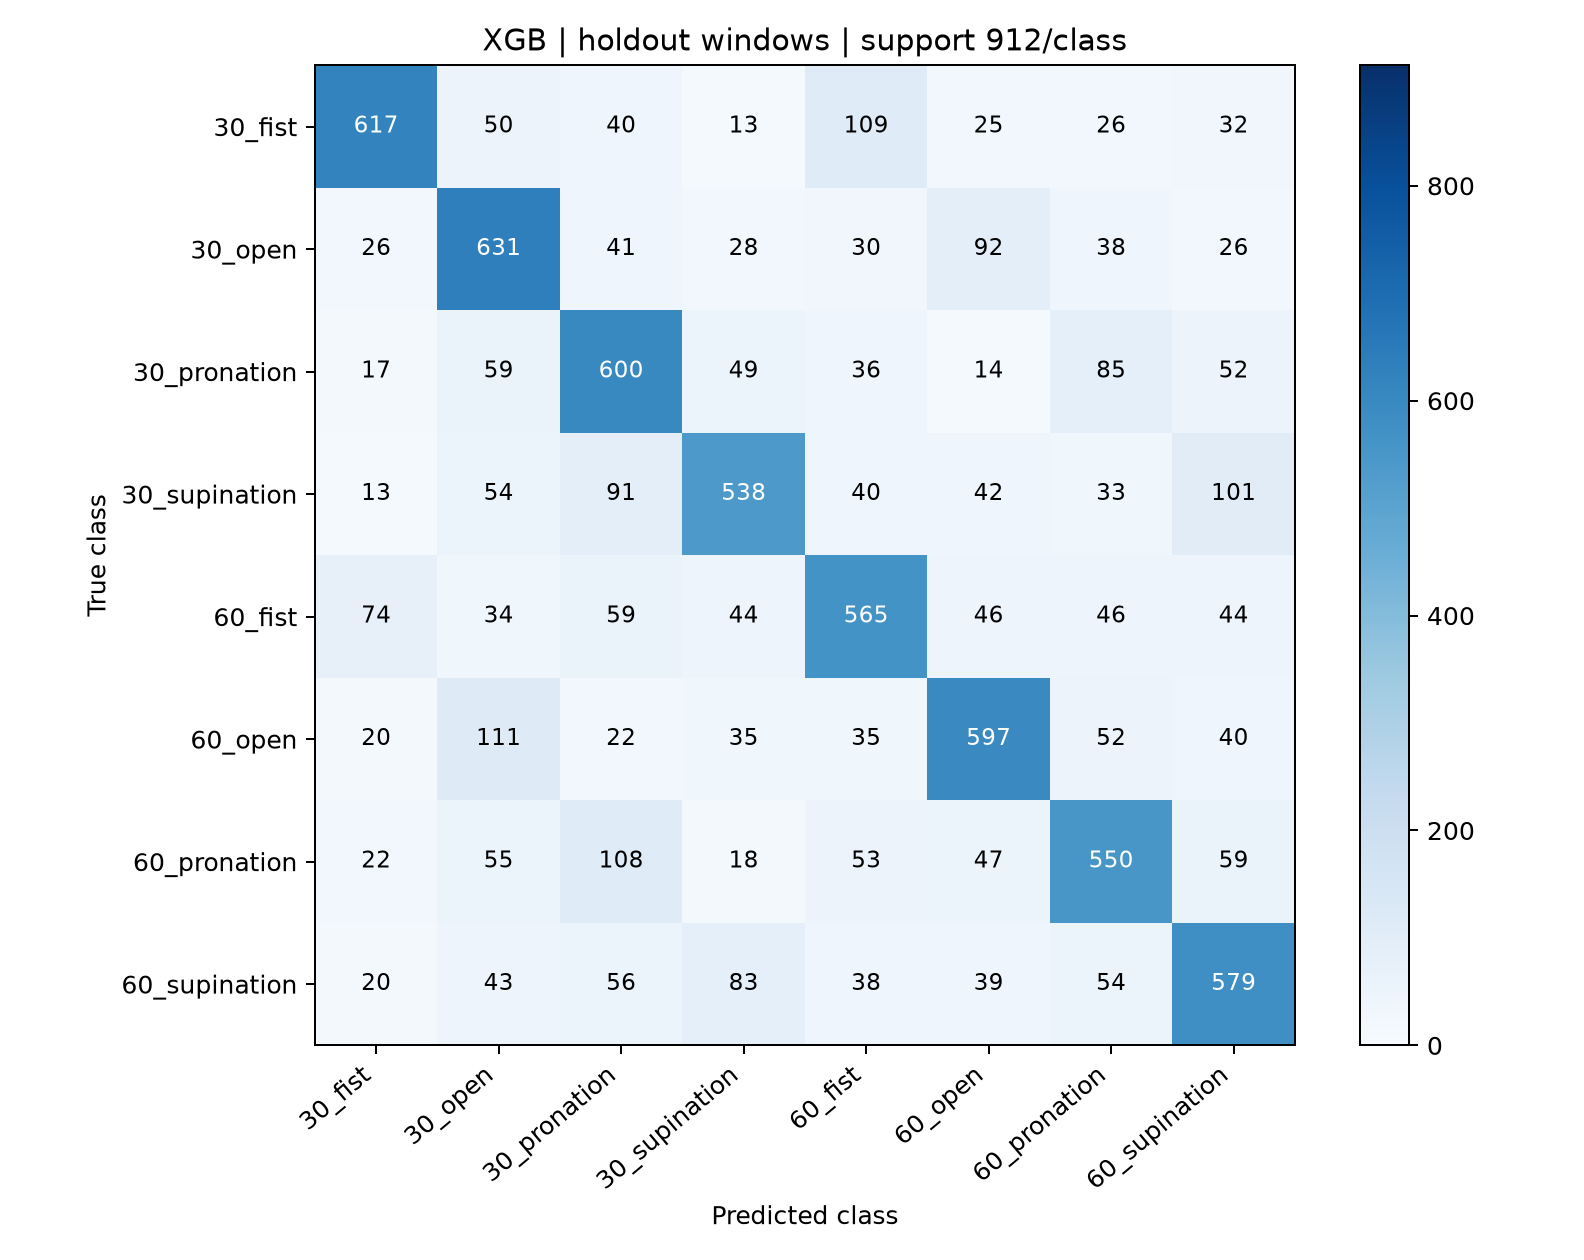

{'confusion': [[617, 50, 40, 13, 109, 25, 26, 32],
  [26, 631, 41, 28, 30, 92, 38, 26],
  [17, 59, 600, 49, 36, 14, 85, 52],
  [13, 54, 91, 538, 40, 42, 33, 101],
  [74, 34, 59, 44, 565, 46, 46, 44],
  [20, 111, 22, 35, 35, 597, 52, 40],
  [22, 55, 108, 18, 53, 47, 550, 59],
  [20, 43, 56, 83, 38, 39, 54, 579]],
 'class_recall': [0.6765350877192983,
  0.6918859649122807,
  0.6578947368421053,
  0.5899122807017544,
  0.6195175438596491,
  0.6546052631578947,
  0.6030701754385965,
  0.6348684210526315],
 'error_types': {'same_gesture_wrong_angle': 763,
  'same_angle_wrong_gesture': 1034,
  'both_wrong': 822},
 'errors': 2619,
 'top_errors': [{'actual': '60_open', 'predicted': '30_open', 'count': 111},
  {'actual': '30_fist', 'predicted': '60_fist', 'count': 109},
  {'actual': '60_pronation', 'predicted': '30_pronation', 'count': 108},
  {'actual': '30_supination', 'predicted': '60_supination', 'count': 101},
  {'actual': '30_open', 'predicted': '60_open', 'count': 92}],
 'best_classes': 

In [5]:
for name in ['SVM','RF','XGB']:
    print(name)
    display(Image(filename=str(OUT/f'confusion_{name}.png')))
    display(r['errors'][name])

## 한계와 결과 추적
동일 피험자·기록의 다른 시행은 양쪽 분할에 존재한다. 실제 동작 정렬은 미확인이고, 고정된 강의 파라미터를 사용했다. 논문 수치와의 차이를 성능 실패 또는 누수의 단독 증거로 해석하지 않는다. 결과보고서의 환경·통계 검정·계산 비용 한계를 함께 읽어야 한다.

`python verify_week3.py`는 저장된 예측으로 지표와 혼동행렬, 통계 검정을 재계산하고 시행 분리·라벨 대응·입력 해시를 검증한다.